In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.animation as animation

# Load dataset (update filename if your local CSV has a slightly different name)
df = pd.read_csv('spotify_top_1000_tracks.csv')

# Student-specific personalization parameters
student_name = "Sydney Yueen Rhave T. Sabida"
student_id = "TUPM-26-1157"

Top 10 Longest Tracks - Sydney Yueen Rhave T. Sabida (TUPM-26-1157)
                                     track_name                artist  duration_min
                                       Lost Boy                 Jaden      9.497883
                              I'm Getting Ready   Tasha Cobbs Leonard      8.436667
                                        Mirrors     Justin Timberlake      8.069100
What Goes Around.../...Comes Around (Interlude)     Justin Timberlake      7.476217
                             Achilles Come Down        Gang of Youths      7.035767
                           Never Let Go (Of Me)                Baltra      6.909833
          House Of Balloons / Glass Table Girls            The Weeknd      6.753550
                                           Stan                Eminem      6.735100
                                      Galvanize The Chemical Brothers      6.563550
                                    After Hours            The Weeknd      6.017100


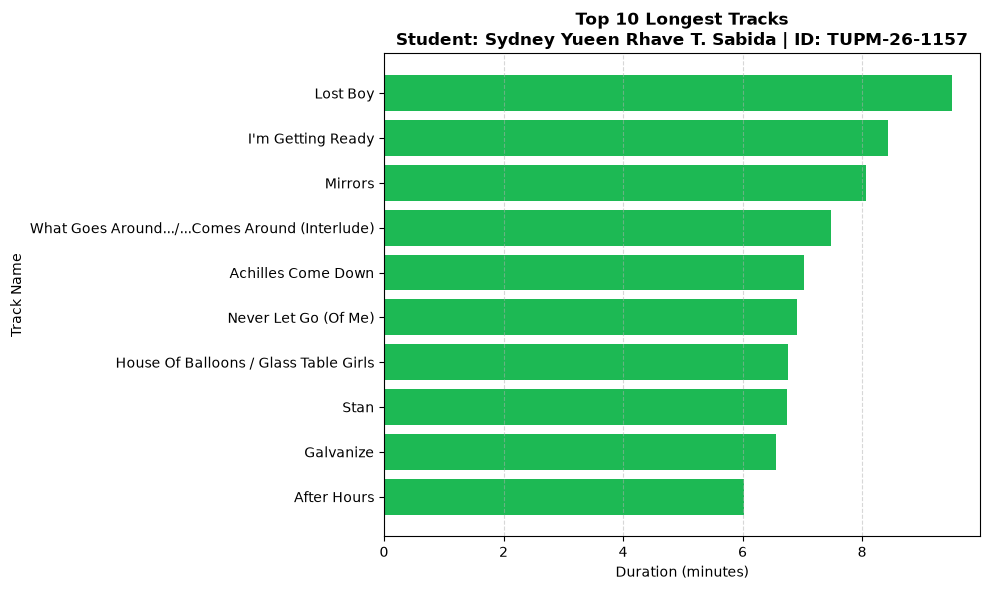

In [6]:
# Parameters for Exercise 1
color_bar = "#1DB954"  # Spotify Green (customize as desired)

# Clean and sort data by duration_min in descending order
df_ex1 = df[['track_name', 'artist', 'duration_min']].dropna()
df_ex1['duration_min'] = pd.to_numeric(df_ex1['duration_min'], errors='coerce')
top_10_longest = df_ex1.sort_values(by='duration_min', ascending=False).head(10)

# Output 1: Display table of top 10 longest tracks
print(f"Top 10 Longest Tracks - {student_name} ({student_id})")
print(top_10_longest.to_string(index=False))

# Output 2: Horizontal bar chart (invert y-axis so the #1 longest track is at the top)
plt.figure(figsize=(10, 6))
plt.barh(top_10_longest['track_name'], top_10_longest['duration_min'], color=color_bar)
plt.gca().invert_yaxis()

plt.title(f"Top 10 Longest Tracks\nStudent: {student_name} | ID: {student_id}", fontsize=12, fontweight='bold')
plt.xlabel("Duration (minutes)")
plt.ylabel("Track Name")
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()
plt.close()

In [8]:
print(df.columns.tolist())

['track_name', 'artist', 'album', 'release_date', 'popularity', 'spotify_url', 'id', 'duration_min']


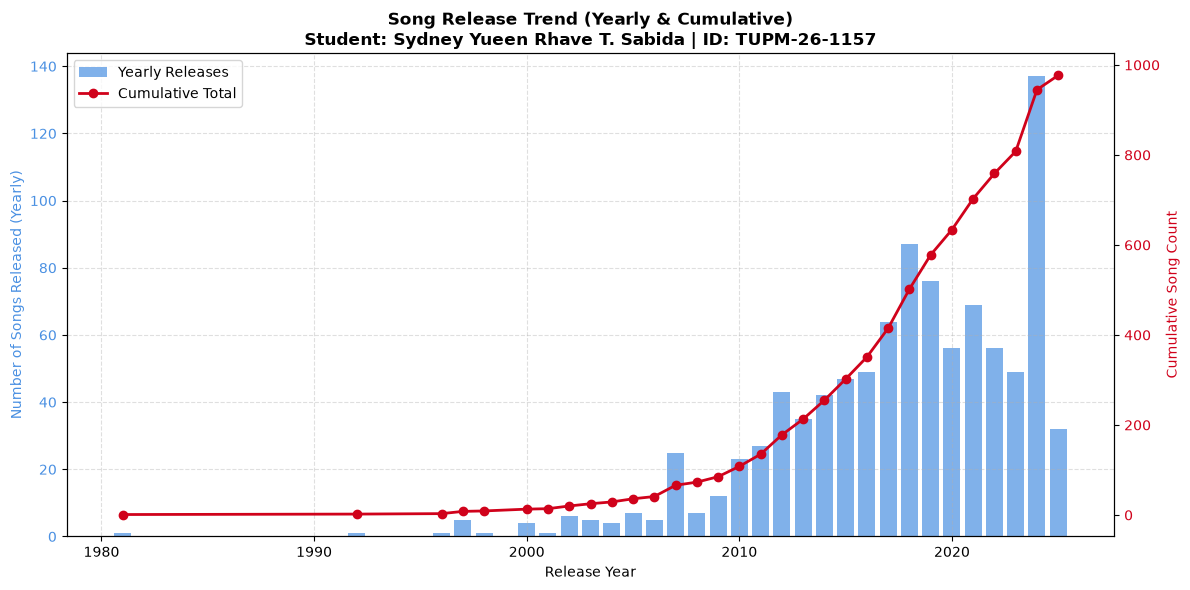

In [9]:
# Parameters for Exercise 2
color_bar = "#4A90E2"   # Blue for yearly counts
color_line = "#D0021B"  # Red for cumulative growth

# Normalize column names (strip spaces & lowercase for matching)
col_map = {col.strip().lower(): col for col in df.columns}

# Look for a year column first, otherwise extract year from a date column
year_candidates = ['year', 'release_year', 'album_release_year', 'yr']
date_candidates = ['release_date', 'date']

matched_year_col = next((col_map[c] for c in year_candidates if c in col_map), None)
matched_date_col = next((col_map[c] for c in date_candidates if c in col_map), None)

if matched_year_col:
    years_series = pd.to_numeric(df[matched_year_col], errors='coerce')
elif matched_date_col:
    years_series = pd.to_datetime(df[matched_date_col], errors='coerce').dt.year
else:
    raise KeyError(
        f"No 'year' or release date column found. Available columns: {df.columns.tolist()}"
    )

df_ex2 = pd.DataFrame({'year': years_series}).dropna().copy()
df_ex2['year'] = df_ex2['year'].astype(int)

yearly_counts = df_ex2.groupby('year').size().reset_index(name='song_count')
yearly_counts = yearly_counts.sort_values(by='year')
yearly_counts['cumulative_count'] = yearly_counts['song_count'].cumsum()

# Output: Combined bar + line chart
fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.bar(
    yearly_counts['year'],
    yearly_counts['song_count'],
    color=color_bar,
    alpha=0.7,
    label='Yearly Releases'
)
ax1.set_xlabel("Release Year")
ax1.set_ylabel("Number of Songs Released (Yearly)", color=color_bar)
ax1.tick_params(axis='y', labelcolor=color_bar)

ax2 = ax1.twinx()
ax2.plot(
    yearly_counts['year'],
    yearly_counts['cumulative_count'],
    color=color_line,
    marker='o',
    linewidth=2,
    label='Cumulative Total'
)
ax2.set_ylabel("Cumulative Song Count", color=color_line)
ax2.tick_params(axis='y', labelcolor=color_line)

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left')

plt.title(
    f"Song Release Trend (Yearly & Cumulative)\nStudent: {student_name} | ID: {student_id}",
    fontsize=12,
    fontweight='bold'
)
ax1.grid(True, linestyle='--', alpha=0.4)
fig.tight_layout()
plt.show()
plt.close()

In [12]:
from IPython.display import HTML  # Placed at top level (no leading spaces)

# Parameters for Exercise 3
cmap_color = "viridis"  # Colormap for hexbin density

# Normalize column names for flexible matching
col_map = {col.strip().lower(): col for col in df.columns}

duration_col = next((col_map[c] for c in ['duration_min', 'duration', 'duration_ms'] if c in col_map), None)
popularity_col = next((col_map[c] for c in ['popularity', 'pop'] if c in col_map), None)
year_col = next((col_map[c] for c in ['year', 'release_year', 'album_release_year', 'yr'] if c in col_map), None)
date_col = next((col_map[c] for c in ['release_date', 'date'] if c in col_map), None)

if not duration_col or not popularity_col:
    raise KeyError(f"Missing duration or popularity column. Available columns: {df.columns.tolist()}")

duration_series = pd.to_numeric(df[duration_col], errors='coerce')
if duration_col == 'duration_ms':
    duration_series = duration_series / 60000.0  # Convert ms to minutes if needed

popularity_series = pd.to_numeric(df[popularity_col], errors='coerce')

if year_col:
    year_series = pd.to_numeric(df[year_col], errors='coerce')
elif date_col:
    year_series = pd.to_datetime(df[date_col], errors='coerce').dt.year
else:
    raise KeyError(f"No 'year' or release date column found. Available columns: {df.columns.tolist()}")

df_ex3 = pd.DataFrame({
    'duration_min': duration_series,
    'popularity': popularity_series,
    'year': year_series
}).dropna().copy()
df_ex3['year'] = df_ex3['year'].astype(int)

years = sorted(df_ex3['year'].unique())

# Set fixed axis limits across all frames so the animation scale stays consistent
x_min, x_max = df_ex3['duration_min'].min(), df_ex3['duration_min'].max()
y_min, y_max = df_ex3['popularity'].min(), df_ex3['popularity'].max()

fig, ax = plt.subplots(figsize=(9, 6))

initial_data = df_ex3[df_ex3['year'] == years[0]]
hb = ax.hexbin(
    initial_data['duration_min'],
    initial_data['popularity'],
    gridsize=20,
    cmap=cmap_color,
    extent=(x_min, x_max, y_min, y_max),
    mincnt=1
)
cb = fig.colorbar(hb, ax=ax, label='Song Concentration (Count)')

def update(frame_year):
    ax.clear()
    subset = df_ex3[df_ex3['year'] == frame_year]
    ax.hexbin(
        subset['duration_min'],
        subset['popularity'],
        gridsize=20,
        cmap=cmap_color,
        extent=(x_min, x_max, y_min, y_max),
        mincnt=1
    )
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xlabel("Duration (minutes)")
    ax.set_ylabel("Popularity Score")
    ax.set_title(
        f"Duration vs Popularity Density ({frame_year})\nStudent: {student_name} | ID: {student_id}",
        fontsize=11,
        fontweight='bold'
    )
    ax.grid(True, linestyle='--', alpha=0.4)

ani = animation.FuncAnimation(fig, update, frames=years, interval=600, repeat=True)

# For Jupyter Notebook:
plt.close(fig)
HTML(ani.to_jshtml())

# If running as a .py script instead of Jupyter, comment out the two lines above and uncomment:
# plt.show()